# Flood Reconstruction — Sensor-Budget Study

Compare 16, 32, 64, and 128 virtual sensors across seeds 42, 43, and 44. This notebook reads the executed experiment results. Reproduce training with `floods sensor-ablation` from the repository root.

## 1. Load Experiment Results

Each seed uses nested sensors and fixed validation/test locations across budgets. The measured-model training code comes directly from the main notebook; the simulated PINN experiment is separate.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "reports/sensor_ablation/runs.csv").is_file())
REPORTS = ROOT / "reports/sensor_ablation"
runs = pd.read_csv(REPORTS / "runs.csv")
summary = pd.read_csv(REPORTS / "summary.csv")
protocol = json.loads((REPORTS / "protocol.json").read_text())
print("Seeds:", protocol["seeds"])
print("Sensor budgets:", protocol["sensor_budgets"])
print("MLP optimizer steps:", protocol["mlp_steps"])
runs.head()

Seeds: [42, 43, 44]
Sensor budgets: [16, 32, 64, 128]
MLP optimizer steps: 1500


,Model,RMSE (mm),MAE (mm),R²,95th abs. error (mm),Sensors,Seed,Split,Steps,Selected by validation
0,Interpolation,3.050106,1.926262,0.970675,5.519005,128,42,validation,1500,True
1,Random Forest,3.811504,2.435819,0.954207,7.677804,128,42,validation,1500,False
2,MLP,4.743167,3.342309,0.929084,9.397150,128,42,validation,1500,False
3,Polynomial Ridge,5.909192,4.466430,0.889932,11.513511,128,42,validation,1500,False
4,Interpolation,3.024009,1.942771,0.970696,5.477647,128,42,test,1500,True


## 2. Wave 1 Reconstruction

Report test RMSE in millimeters. The mean and sample standard deviation summarize three seeds, which vary both sensor placement and neural initialization.

In [2]:
test = summary[summary.Split == "test"].copy()
test["RMSE mean ± std (mm)"] = test.apply(
    lambda row: f"{row.rmse_mean_mm:.2f} ± {row.rmse_std_mm:.2f}", axis=1)
test.pivot(index="Sensors", columns="Model", values="RMSE mean ± std (mm)")

Model,Interpolation,MLP,Polynomial Ridge,Random Forest
Sensors,,,,
16,5.52 ± 0.12,5.45 ± 0.12,7.46 ± 1.55,5.60 ± 0.11
32,4.70 ± 0.22,5.24 ± 0.18,6.16 ± 0.01,5.02 ± 0.17
64,3.76 ± 0.35,4.88 ± 0.04,5.95 ± 0.08,4.51 ± 0.07
128,3.16 ± 0.13,4.82 ± 0.12,5.91 ± 0.05,3.81 ± 0.08


## 3. Reconstruction and Frozen Transfer

Error bars show sample standard deviation, not confidence intervals. Transfer uses wave 3 from the same laboratory geometry without retraining.

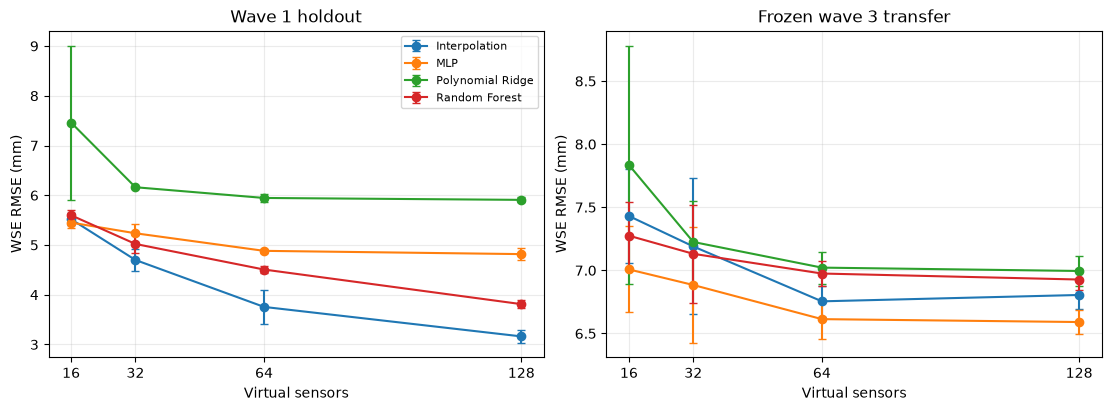

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, split in zip(axes, ["test", "transfer"]):
    for model, frame in summary[summary.Split == split].groupby("Model"):
        ax.errorbar(frame.Sensors, frame.rmse_mean_mm, yerr=frame.rmse_std_mm,
                    marker="o", capsize=3, label=model)
    ax.set(title="Wave 1 holdout" if split == "test" else "Frozen wave 3 transfer",
           xlabel="Virtual sensors", ylabel="WSE RMSE (mm)", xticks=[16, 32, 64, 128])
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.show()

## 4. Validation-Based Selection

Model selection uses validation RMSE. The table counts how often each model was selected across the three seeds; the transfer set is never used to choose a model.

In [4]:
selected = runs[(runs.Split == "validation") & runs["Selected by validation"]]
pd.crosstab(selected.Sensors, selected.Model)

Model,Interpolation,Random Forest
Sensors,,
16,2,1
32,3,0
64,3,0
128,3,0


## Conclusion

Interpolation improves from 5.52 mm mean test RMSE at 16 sensors to 3.16 mm at 128 sensors. The MLP has slightly lower mean test error at 16 sensors, but the difference is small and does not establish statistical superiority. Frozen wave 3 transfer errors remain higher than within-wave reconstruction errors.

These are paired results from one laboratory configuration, with a different sensor sampling design from the original showcase. They do not measure variability across independent flood events or repeat the single-seed PINN benchmark.